# Training the MRAi_P3 2D-US model locally — step by step

Executable companion to [`docs/local_training.md`](local_training.md). Every command
below was validated on a MacBook Air M1 (8 cores, 16 GB), **CPU only**. Run the
cells in order; each one prints what it is doing and checks its own result.

**What this notebook does**

| # | Stage | Script | Cost (measured, M1 CPU) |
|---|---|---|---|
| 1 | Pre-extract the background pool | `scripts/preextract.py` | ~30 s – 2 min, once |
| 2 | Smoke test (1 epoch, full data) | `scripts/train_model.py` | ~30 s |
| 3 | Full fine-tune (210 epochs) | `scripts/train_model.py` | **~1 – 1.5 h** |
| 4 | Ring metric + the whole chain on a real spectrum | `scripts/bruker_2d/run_51.py` | ~1 min |

**Before you start:** the training set is built from cross-sections ("rows") of each
256×2048 spectrum. The expensive split is deterministic; only the background sampling is
random. Stage 1 pays the split **once** and stores a pool; stage 3 subsamples that pool
every epoch, so the background keeps varying while the split is never recomputed.

> **Local or Colab?** This machine has **no GPU** (`tf.config.list_physical_devices("GPU")`
> is empty and TensorFlow has no Metal backend). A full 210-epoch run costs ~1–1.5 h here
> versus minutes on a free Colab T4. Use this notebook for **short runs, debugging and
> reproducibility**; use [`colab/MRAi_Colab_Train.ipynb`](../colab/MRAi_Colab_Train.ipynb)
> for the long ones. The pipeline, the flags and the outputs are the same.

## 0. Requirements

* **This checkout** (`scripts/train_model.py` must exist) — the notebook finds the repo
  root by walking up from the working directory.
* **The Phase 1 dataset**, e.g. `/Users/abolanos/git/cheminfo/spectrum-generator/dataset`:
  `spectra/*.bin` (float32 LE) + `labels/*.bin` (uint8), 1000 spectra, ~2.5 GB.
* **A manifest with the 800/200 split**: `data/train_2d_elong/manifest.json`
  (produced by `scripts/jres_ingest.py`).
* **A Python 3.10–3.13 environment with TensorFlow ≥ 2.15** (arm64-native).

### The environment pitfall that costs the most time

On this machine there are two pyenv virtualenvs:

| env | TensorFlow | Jupyter |
|---|---|---|
| `jres` (the default) | **no** | yes |
| `tflow` | **yes** (2.21.0, Keras 3.x) | no |

So the env that runs Jupyter is **not** the env that can train. Rather than install
anything, this notebook is a **driver**: it locates a Python that can `import
tensorflow` and shells the pipeline out to it, so it works from *either* kernel.

If you would rather have a single kernel that can train, create one once:

```bash
~/.pyenv/versions/3.13.2/envs/tflow/bin/python -m pip install ipykernel
~/.pyenv/versions/3.13.2/envs/tflow/bin/python -m ipykernel install --user \
    --name mrai-p3-tflow --display-name "MRAi_P3 (tflow, TF)"
```

then pick **MRAi_P3 (tflow, TF)** in *Kernel ▸ Change Kernel*.

In [1]:
import glob, os, shutil, subprocess, sys, time

def find_repo_root(start=None):
    """Walk up from `start` until we find scripts/train_model.py."""
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isfile(os.path.join(d, "scripts", "train_model.py")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise RuntimeError(
                "repo root not found: no scripts/train_model.py above " + os.getcwd())
        d = parent

REPO = find_repo_root()
os.chdir(REPO)
print("repo:", REPO)

def tf_version(py):
    """TensorFlow version importable from `py`, or None."""
    try:
        r = subprocess.run(
            [py, "-c", "import tensorflow as tf; print(tf.__version__)"],
            capture_output=True, text=True, timeout=300)
    except Exception:
        return None
    return r.stdout.strip().splitlines()[-1] if r.returncode == 0 else None

def find_tf_python():
    """Candidate interpreters, best first: the current kernel, then pyenv envs.

    Deliberately NOT de-duplicated by `os.path.realpath`: a pyenv virtualenv's
    `bin/python` is a **symlink to the base interpreter**, so `jres`, `tflow`
    and the base `3.13.2` all resolve to the same real path while being
    different environments -- here `tflow` has TensorFlow and `jres` does not.
    Collapsing them would silently skip the only usable env.
    """
    cands = [sys.executable]
    for pat in ("~/.pyenv/versions/*/envs/*/bin/python",   # pyenv-virtualenv
                "~/.pyenv/versions/*/bin/python",          # plain pyenv
                "~/miniconda3/envs/*/bin/python", "~/anaconda3/envs/*/bin/python"):
        cands += sorted(glob.glob(os.path.expanduser(pat)))
    cands += [shutil.which("python3"), shutil.which("python")]
    return [c for c in dict.fromkeys(cands) if c and os.path.exists(c)]

print("\nLooking for an interpreter that can import TensorFlow (first hit wins):")
PY = None
for cand in find_tf_python():
    v = tf_version(cand)
    print(f"  {'TF ' + v if v else '  no TF'}  {cand}", flush=True)
    if v:
        PY = cand
        break

if PY is None:
    raise RuntimeError(
        "No Python with TensorFlow was found. Create or activate one (see the cell "
        "above), e.g. `pyenv activate tflow`, then re-run this cell.")

print(f"\nUsing: {PY}")
print(subprocess.run([PY, "-c",
      "import tensorflow as tf; print('TF', tf.__version__, "
      "'| GPUs:', tf.config.list_physical_devices('GPU'), '| CPU only')"],
      capture_output=True, text=True).stdout.strip())


repo: /Users/abolanos/git/mrai_p3

Looking for an interpreter that can import TensorFlow (first hit wins):
  TF 2.21.0  /Users/abolanos/.pyenv/versions/tflow/bin/python

Using: /Users/abolanos/.pyenv/versions/tflow/bin/python
TF 2.21.0 | GPUs: [] | CPU only


In [2]:
# ---------------------------------------------------------------------------
# Paths and the one helper every later cell uses.  Change DATASET / OUT here
# (and only here) if your layout differs.
# ---------------------------------------------------------------------------
DATASET  = "/Users/abolanos/git/cheminfo/spectrum-generator/dataset"
IDS      = "data/train_2d_elong/manifest.json"          # Phase 1 split (800/200)
POOL     = "data/pre_elong"                             # pre-extracted pool
INIT     = "Trained/Probability_2D/US/DNN_0"            # fine-tune base SavedModel
OUT      = "Trained/Probability_2D_Elongated/DNN_0_local"   # fresh dir, see Pitfalls
LOG      = "/tmp/retrain_fase2.log"                     # stdout of the full run
SMOKE    = "/tmp/smoke_local"

# Pre-extraction parameters.  pool_k MUST stay > the training --bg-ratio (4)
# so each epoch draws a different background subset from the pool.
SEED, POOL_K, HARD_FRAC, HARD_PX = 0, 10, 0.5, 2

# Training parameters (paper-like config: 35 train / 8 val steps per epoch).
LR, BATCH, BG_RATIO, EPOCHS, PATIENCE = 1e-4, 65536, 4, 210, 20


def run(args, timeout=None, quiet=False):
    """Run a pipeline command in the TensorFlow env; stream its output."""
    argv = [PY, *[str(a) for a in args]]
    print("$", " ".join(argv[1:]), "\n", flush=True)
    t0 = time.time()
    p = subprocess.run(argv, cwd=REPO, timeout=timeout,
                       stdout=subprocess.DEVNULL if quiet else None)
    dt = time.time() - t0
    print(f"\n[exit {p.returncode} — {dt:.1f} s ({dt / 60:.1f} min)]")
    if p.returncode != 0:
        raise RuntimeError(f"command failed with exit code {p.returncode}")
    return dt

print(f"DATASET : {DATASET}")
print(f"IDS     : {IDS}")
print(f"POOL    : {POOL}")
print(f"INIT    : {INIT}")
print(f"OUT     : {OUT}")

DATASET : /Users/abolanos/git/cheminfo/spectrum-generator/dataset
IDS     : data/train_2d_elong/manifest.json
POOL    : data/pre_elong
INIT    : Trained/Probability_2D/US/DNN_0
OUT     : Trained/Probability_2D_Elongated/DNN_0_local


## 1. Stage map

```
dataset/*.bin ──preextract.py──▶ data/pre_elong/*.npz ──train_model.py──▶ <out> + <out>_savedmodel/
 (1000 spectra)   split once      pool: all positives     subsample         ckpt.keras · training.log
                                  + hard_frac ring        every epoch       history.npy · SavedModel
                                  + rest of background
```

The label is a sub-pixel marker (1/2/4 px per peak; 2.26 on average) while a peak spans
~20–50 px, so the zeros **inside** a peak are where the false positives live. Sampling the
background uniformly over all zeros put those at 0.48 % of the pool, and the trained model
ended up giving `P > 0.5` to **81 %** of the zeros immediately next to a peak — the learned
boundary sat at ~2–3 px instead of the label's ~0.5–1 px, and the peak list came out ~7.7×
too long. `--hard-frac` reserves a share of the background for that ring (`d <= --hard-px`),
and every pool row stores its distance to the nearest peak in `d` so the per-epoch share can
be tuned at training time without regenerating the pool.

In [3]:
# --- Check inputs before spending any time ---------------------------------
import json

problems = []
if not os.path.isdir(os.path.join(DATASET, "spectra")):
    problems.append(f"missing {DATASET}/spectra")
if not os.path.isfile(os.path.join(REPO, IDS)):
    problems.append(f"missing {IDS} — run scripts/jres_ingest.py first "
                    "(see colab/COLAB.md §3)")
if not os.path.isdir(os.path.join(REPO, INIT)):
    problems.append(f"missing {INIT} — the fine-tune base SavedModel")
if problems:
    raise SystemExit("Cannot continue:\n  - " + "\n  - ".join(problems))

n_spec = len(glob.glob(os.path.join(DATASET, "spectra", "*.bin")))
size_gb = sum(os.path.getsize(os.path.join(DATASET, d, f))
              for d in ("spectra", "labels")
              for f in os.listdir(os.path.join(DATASET, d))) / 1e9
man = json.load(open(os.path.join(REPO, IDS)))
print(f"dataset  : {n_spec} spectra, {size_gb:.1f} GB  ({DATASET})")
print(f"manifest : {len(man['train'])} train / {len(man['val'])} val  ({IDS})")
print(f"           source = {man.get('source')}")
print(f"base     : {INIT}")
INIT_IS_BASE = "Probability_2D/US/DNN_0" in INIT.replace("\\", "/")
print(f"           fine-tune base (2D-US): {INIT_IS_BASE}")
assert INIT_IS_BASE or os.path.isdir(os.path.join(REPO, INIT))

dataset  : 1000 spectra, 2.6 GB  (/Users/abolanos/git/cheminfo/spectrum-generator/dataset)
manifest : 800 train / 200 val  (data/train_2d_elong/manifest.json)
           source = /Users/abolanos/git/cheminfo/spectrum-generator/dataset
base     : Trained/Probability_2D/US/DNN_0
           fine-tune base (2D-US): True


## 2. Step 1 — Pre-extraction (once)

Runs `split_2d` **once per spectrum** and stores a pool: all positives, the `--hard-frac`
share of the ring, and the rest of the background (`pool_k × n_pos` rows total). Training
then subsamples it every epoch.

* `--hard-frac 0.25` (default) reserves 25 % of the pool's background for negatives within
  `--hard-px 2` px of a peak. `--hard-frac 0` reproduces the old uniform background
  byte-for-byte (that is the pool pinned by `tests/test_split_rows.py`).
* `--fast` is a **documented no-op**: the row-wise `split_2d_rows` is the default path now.
  `--slow-split` forces the reference full-matrix path, for verification only.
* **`pool_k` must be greater than the training `--bg-ratio`** (10 > 4) so each epoch sees a
  different background subset. With `pool_k == bg_ratio` the whole pool is consumed every
  epoch (fixed sampling).

> **Re-run this if `data/pre_elong/` is missing or stale.** The pool currently in this
> checkout was written **before** the hard-negative ring existed: its `manifest.json` has no
> `hard_frac` and its `.npz` files have no `d`. `train_model.py` **refuses** to run with
> `--hard-frac > 0` on such a pool (it would silently train with the uniform background), so
> the cell below regenerates it. The cell after it verifies the result either way.

In [4]:
run([f"scripts/preextract.py",
     "--dataset", DATASET,
     "--ids", IDS,
     "--out", POOL,
     "--seed", SEED,
     "--pool-k", POOL_K,
     "--hard-frac", HARD_FRAC,
     "--hard-px", HARD_PX,
     "--fast"])                      # --fast is a no-op, kept for Colab parity

$ scripts/preextract.py --dataset /Users/abolanos/git/cheminfo/spectrum-generator/dataset --ids data/train_2d_elong/manifest.json --out data/pre_elong --seed 0 --pool-k 10 --hard-frac 0.5 --hard-px 2 --fast 

[25/1000] 0027 M=6303 0.1s (elapsed 0 min, ETA 2 min)
[50/1000] 0060 M=6237 0.1s (elapsed 0 min, ETA 2 min)
[75/1000] 0091 M=6490 0.1s (elapsed 0 min, ETA 2 min)
[100/1000] 0121 M=6391 0.1s (elapsed 0 min, ETA 2 min)
[125/1000] 0150 M=6314 0.1s (elapsed 0 min, ETA 2 min)
[150/1000] 0180 M=6237 0.1s (elapsed 0 min, ETA 2 min)
[175/1000] 0210 M=6347 0.1s (elapsed 0 min, ETA 2 min)
[200/1000] 0241 M=6380 0.1s (elapsed 0 min, ETA 2 min)
[225/1000] 0268 M=6105 0.1s (elapsed 0 min, ETA 2 min)
[250/1000] 0298 M=6391 0.1s (elapsed 1 min, ETA 2 min)
[275/1000] 0326 M=5995 0.1s (elapsed 1 min, ETA 1 min)
[300/1000] 0355 M=6479 0.1s (elapsed 1 min, ETA 1 min)
[325/1000] 0383 M=6292 0.1s (elapsed 1 min, ETA 1 min)
[350/1000] 0416 M=6281 0.1s (elapsed 1 min, ETA 1 min)
[375/1000] 0447 M=6248 0

115.83461809158325

In [7]:
# --- Verify the pool: the file that training will actually read ------------
import numpy as np

pool_man_path = os.path.join(REPO, POOL, "manifest.json")
assert os.path.isfile(pool_man_path), f"missing {POOL}/manifest.json"
pman = json.load(open(pool_man_path))
npz = sorted(glob.glob(os.path.join(REPO, POOL, "*.npz")))

keys = {}
with np.load(npz[0]) as z:
    keys = {k: (z[k].shape, str(z[k].dtype)) for k in z.files}

print(f"pool   : {len(npz)} .npz  "
      f"({sum(os.path.getsize(f) for f in npz) / 1e9:.1f} GB)")
print(f"         train {len(pman['train'])} / val {len(pman['val'])}")
print(f"         seed={pman.get('seed')}  pool_k={pman.get('pool_k')}  "
      f"hard_frac={pman.get('hard_frac')}  hard_px={pman.get('hard_px')}")
print(f"first npz keys: {keys}")

# Every pool file must carry `d`: a mixed pool (some with, some without) would
# train those spectra with a uniform background without saying anything.
missing_d = []
for f in npz:
    with np.load(f) as z:
        if "d" not in z.files:
            missing_d.append(os.path.basename(f))
has_d = not missing_d
rows = np.array([np.load(f)["X"].shape[0] for f in npz[:25]])
print(f"M (pool rows) : mean {rows.mean():.0f} over the first {len(rows)} spectra")

# The two conditions train_model.py will enforce:
if HARD_FRAC > 0 and missing_d:
    raise SystemExit(f"{len(missing_d)}/{len(npz)} pools have no `d` "
                     f"(e.g. {missing_d[:3]}): re-run the cell above, or train "
                     f"with --hard-frac 0 (uniform background)")
if pman.get("pool_k", 0) <= BG_RATIO:
    raise SystemExit(f"pool_k ({pman.get('pool_k')}) must exceed --bg-ratio "
                     f"({BG_RATIO}) for the background to vary between epochs")
print("\nOK: pool is usable with the training parameters in this notebook.")

# --- Pre-flight: one epoch's sample must fill at least one batch -----------
# The generator only emits a batch once it has `batch` rows, so an epoch with
# fewer rows produces nothing: training aborts with the loud `_StepGuard`
# message and *validation* comes out NaN silently (that is the NA that used to
# break the monitoring cell). Pair a reduced --n-train with a smaller --batch.
def epoch_rows(ids):
    with np.load(os.path.join(REPO, POOL, f"{ids[0]}.npz")) as z:
        n_pos, M = int(z["n_pos"]), int(z["X"].shape[0])
    return len(ids) * min(M, n_pos * (1 + BG_RATIO))

pool_problems = []
for split, ids in (("train", pman["train"]), ("val", pman["val"])):
    rows = epoch_rows(ids)
    ok = rows >= BATCH
    print(f"  {'OK ' if ok else '!! '} {split}: {len(ids)} spectra x "
          f"{rows // max(len(ids), 1)} rows/epoch = {rows} rows vs --batch {BATCH}")
    if not ok:
        pool_problems.append(
            f"{split} epoch has {rows} rows < --batch {BATCH}: lower --batch "
            f"or use more spectra (--n-train / more of the manifest)")
if pool_problems:
    raise SystemExit("Cannot continue:\n  - " + "\n  - ".join(pool_problems))


pool   : 1000 .npz  (3.3 GB)
         train 800 / val 200
         seed=0  pool_k=10.0  hard_frac=0.25  hard_px=2
first npz keys: {'X': ((6424, 128, 1), 'float32'), 'y': ((6424, 1), 'float32'), 'n_pos': ((), 'int32'), 'd': ((5840,), 'uint8'), 'hard_px': ((), 'int32'), 'H': ((), 'int32'), 'W': ((), 'int32')}
M (pool rows) : mean 6342 over the first 25 spectra

OK: pool is usable with the training parameters in this notebook.
  OK  train: 800 spectra x 2905 rows/epoch = 2324000 rows vs --batch 65536
  OK  val: 200 spectra x 2920 rows/epoch = 584000 rows vs --batch 65536


## 3. Step 2 — Smoke test first

Two cheap checks of the exact production command before committing an hour to it.

> **`_StepGuard` wants at least one full batch.** Partial trailing batches are discarded by
> design, so a tiny subset with a huge batch (e.g. `--n-train 8 --batch 65536` → ~23 k
> samples) yields 0 batches and training aborts with
> `RuntimeError: epoca 0: 0 batches de entrenamiento…`. That is the safety net for the
> 15-oct silent empty-epoch bug doing its job, **not** a pipeline bug. Always pair a
> `--n-train` reduction with a proportionally smaller `--batch`.

In [8]:
# ~10 s: 8 spectra, small batch, weights copied from the base by role
run([f"scripts/train_model.py",
     "--data", POOL, "--preextracted",
     "--init", INIT, "--lr", LR,
     "--batch", 4096, "--bg-ratio", BG_RATIO,
     "--hard-frac", HARD_FRAC, "--hard-px", HARD_PX,
     "--epochs", 1, "--n-train", 8, "--n-val", 4,
     "--out", SMOKE + "_mini"])

$ scripts/train_model.py --data data/pre_elong --preextracted --init Trained/Probability_2D/US/DNN_0 --lr 0.0001 --batch 4096 --bg-ratio 4 --hard-frac 0.25 --hard-px 2 --epochs 1 --n-train 8 --n-val 4 --out /tmp/smoke_local_mini 

TF 2.21.0 GPUs: []
train 800 / val 200 desde /Users/abolanos/git/cheminfo/spectrum-generator/dataset
fine-tune desde Trained/Probability_2D/US/DNN_0
pesos copiados por rol: 62/62, aleatorios: 0
Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼───��────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 128, 1)    │          0 │ input_layer[0][0] │
├──────────────

/Users/abolanos/.pyenv/versions/tflow/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 126ms/step - acc: 0.8814 - auc: 0.9070 - loss: 0.3774 - val_acc: 0.8899 - val_auc: 0.9129 - val_loss: 0.3576
entrenamiento: 0.00 h
Saved artifact at '/tmp/smoke_local_mini_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  4654957008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4654957968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4654957776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4654958352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4650171280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4653067024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4653066256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4653065872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4654957392: TensorSpec(s

10.21946382522583

In [9]:
# ~30 s: the real thing, one epoch over all 800 train spectra (35 steps)
run([f"scripts/train_model.py",
     "--data", POOL, "--preextracted",
     "--init", INIT, "--lr", LR,
     "--batch", BATCH, "--bg-ratio", BG_RATIO,
     "--hard-frac", HARD_FRAC, "--hard-px", HARD_PX,
     "--epochs", 1,
     "--out", SMOKE + "_full"])

$ scripts/train_model.py --data data/pre_elong --preextracted --init Trained/Probability_2D/US/DNN_0 --lr 0.0001 --batch 65536 --bg-ratio 4 --hard-frac 0.25 --hard-px 2 --epochs 1 --out /tmp/smoke_local_full 

TF 2.21.0 GPUs: []
train 800 / val 200 desde /Users/abolanos/git/cheminfo/spectrum-generator/dataset
fine-tune desde Trained/Probability_2D/US/DNN_0
pesos copiados por rol: 62/62, aleatorios: 0
Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼───��────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 128, 1)    │          0 │ input_layer[0][0] │
├─────────────────────┼─────────────

/Users/abolanos/.pyenv/versions/tflow/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


35/35 ━━━━━━━━━━━━━━━━━━━━ 26s 623ms/step - acc: 0.8909 - auc: 0.9149 - loss: 0.3321 - val_acc: 0.8946 - val_auc: 0.9227 - val_loss: 0.3029
entrenamiento: 0.01 h
Saved artifact at '/tmp/smoke_local_full_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  4688132816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4690003152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4690002960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4690003536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4685429456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4688128592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4688127824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4688127440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4690002576: TensorSpe

32.165294885635376

## 4. Step 3 — Full training (210 epochs)

```bash
python scripts/train_model.py \
  --data data/pre_elong --preextracted \
  --init Trained/Probability_2D/US/DNN_0 \
  --lr 1e-4 --batch 65536 --bg-ratio 4 \
  --epochs 210 --patience 20 \
  --out Trained/Probability_2D_Elongated/DNN_0_local
```

| Flag | Meaning |
|---|---|
| `--preextracted` | read the `<id>.npz` pools from `--data` instead of `.bin` + on-demand split |
| `--init .../US/DNN_0` | fine-tune from the 2D-US base. Weights are copied **by role** (`scripts/weight_roles.py`, derived from the base's graph): 62/62, reproducing the base to `maxdiff < 1e-6`. Omit `--init` and pass `--lr 1e-3` to train from scratch |
| `--hard-frac` | share of each epoch's background drawn from the ring (`d <= --hard-px`) instead of uniformly; 0.25 by default, 0 = old uniform background |
| `--hard-px` | radius in px of the ring treated as a hard negative (2) |
| `--bg-ratio 4` | paper-like background: M ≈ 581×5 ≈ **2905** points/spectrum → **35 train / 8 val steps** per epoch |
| `--patience 20` | early stopping on `val_loss` (the 15-oct run never triggered it — it was still improving) |

**Timing (measured on the M1, CPU):** ~0.485 s/step × 35 steps ≈ **~17 s per epoch** →
210 epochs ≈ **1–1.5 h**.

Because that is far too long to sit in a cell, the next cell launches it with `nohup` in the
background and follows the log — the same way you would from a terminal.

> **`--scratch` / `--sync-every` are Colab-only.** They keep Google Drive's variable I/O
> out of the epoch loop. Locally `--out` is already on disk, so omit them.

In [10]:
# Launch the full run detached, then follow its stdout for a few lines.
os.makedirs(os.path.join(REPO, OUT), exist_ok=True)
cmd = [PY, "scripts/train_model.py",
       "--data", POOL, "--preextracted",
       "--init", INIT, "--lr", str(LR),
       "--batch", str(BATCH), "--bg-ratio", str(BG_RATIO),
       "--hard-frac", str(HARD_FRAC), "--hard-px", str(HARD_PX),
       "--epochs", str(EPOCHS), "--patience", str(PATIENCE),
       "--out", OUT]

if os.path.exists(LOG):
    os.replace(LOG, LOG + ".prev")            # keep the previous run's stdout
with open(LOG, "w") as fh:
    pid = subprocess.Popen(cmd, cwd=REPO, stdout=fh, stderr=subprocess.STDOUT).pid

print("launched pid", pid)
print("$", " ".join(cmd[1:]))
print(f"\nmonitor:  tail -f {LOG}")
print(f"          tail -f {OUT}/training.log")
print("\n--- first lines ---")
for _ in range(40):
    time.sleep(1)
    if os.path.getsize(LOG) > 0 and b"Epoch 1/" in open(LOG, "rb").read():
        break
print("".join(open(LOG, errors="replace").readlines()[-25:]))

launched pid 16350
$ scripts/train_model.py --data data/pre_elong --preextracted --init Trained/Probability_2D/US/DNN_0 --lr 0.0001 --batch 65536 --bg-ratio 4 --hard-frac 0.25 --hard-px 2 --epochs 210 --patience 20 --out Trained/Probability_2D_Elongated/DNN_0_local

monitor:  tail -f /tmp/retrain_fase2.log
          tail -f Trained/Probability_2D_Elongated/DNN_0_local/training.log

--- first lines ---
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 20)        │        820 │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 20)        │        820 │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_12         │ (None, 20)        │          0 │ dense[0][0],      │
│ (Multiply)          │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼

## 5. Step 4 — Monitor, and resume if it is interrupted

`ckpt.keras` and `training.log` are written on every improvement/epoch, so a crash or a
reboot costs at most the current epoch.

Watch progress — `training.log` is a CSV with one row per epoch:

```bash
tail -f Trained/Probability_2D_Elongated/DNN_0_local/training.log
```

To continue **exact weights** after an interruption, use `--resume` (never `--init`, which
would re-seed from the base SavedModel and restart from scratch). The cell below also
rotates the partial log first, because `CSVLogger` overwrites `training.log`.

epochs logged : 210  (last: 209)
empty epochs  : 0  (good: every epoch trained)
best val_loss : 0.140650 at epoch 209
val_loss now  : 0.140650


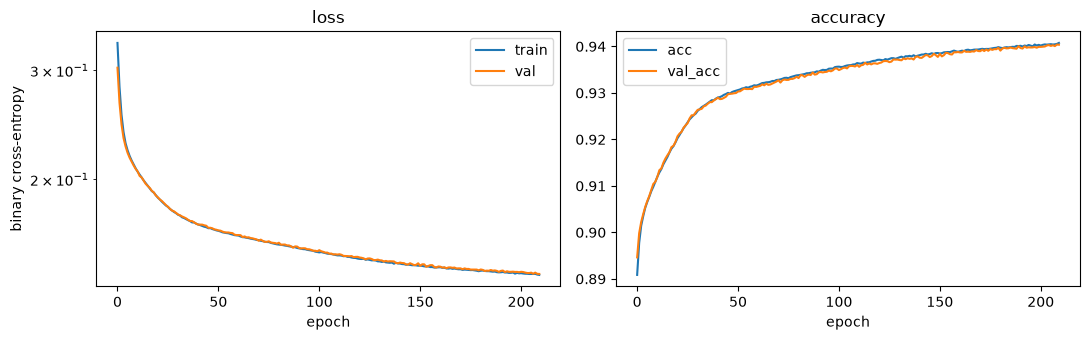

In [15]:
# --- Read the log so far: shape, empty-epoch check, curves ---------------
import csv
import matplotlib.pyplot as plt

log_path = os.path.join(REPO, OUT, "training.log")


def num(row, key):
    """float(row[key]) tolerating the 'NA' CSVLogger writes for a missing metric.

    'NA' is what you get when validation could not fill one batch (see the
    pre-flight check above): before, `float('NA')` crashed this cell.
    """
    v = (row.get(key) or "").strip()
    try:
        return float(v)
    except ValueError:
        return None


if not os.path.isfile(log_path):
    print(f"no log yet at {log_path} — launch the run in the cell above first")
elif not (rows := list(csv.DictReader(open(log_path)))):
    # The run has been launched but no epoch has finished yet (CSVLogger writes
    # the header on the first on_epoch_end), or it died before finishing one.
    print(f"{log_path} exists but holds no epochs yet: the run just started or "
          f"died early. Re-run this cell in a moment.")
else:
    ep = [int(r["epoch"]) for r in rows]
    loss = [num(r, "loss") for r in rows]
    vloss = [num(r, "val_loss") for r in rows]
    zero = [e for e, l in zip(ep, loss) if l == 0.0]
    nan_val = [e for e, v in zip(ep, vloss) if v is None]

    print(f"epochs logged : {len(rows)}  (last: {ep[-1]})")
    print(f"empty epochs  : {len(zero)}"
          + (f"  <-- !! {zero[:10]}" if zero else "  (good: every epoch trained)"))
    if nan_val:
        print(f"val missing   : {len(nan_val)} epoch(s) {nan_val[:5]}  <-- !! "
              f"validation did not fill one batch of {BATCH} rows; see the "
              f"pre-flight check and pitfall 5")
    pairs = [(e, l, v) for e, l, v in zip(ep, loss, vloss) if v is not None]
    if pairs:
        best = min(range(len(pairs)), key=lambda i: pairs[i][2])
        print(f"best val_loss : {pairs[best][2]:.6f} at epoch {pairs[best][0]}")
        print(f"val_loss now  : {pairs[-1][2]:.6f}")

    # An empty epoch is the 15-oct regression: metrics at 0.0, weights frozen.
    # train_model.py now aborts on it (make_step_guard) and to_dataset() uses
    # .repeat() so it cannot happen, but check anyway before trusting the run.
    assert not zero, f"empty epochs found: {zero} — see colab/COLAB.md §8"

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, loss, label="train")
    if pairs:
        ax[0].plot([p[0] for p in pairs], [p[2] for p in pairs], label="val")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("binary cross-entropy")
    ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title("loss")
    ax[1].plot(ep, [num(r, "acc") for r in rows], label="acc")
    ax[1].plot(ep, [num(r, "val_acc") for r in rows], label="val_acc")
    ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("accuracy")
    plt.tight_layout(); plt.show()


In [ ]:
# --- Resume after an interruption (only if you need it) -------------------
# Rename the partial log first: CSVLogger would overwrite it.
log_path = os.path.join(REPO, OUT, "training.log")
ckpt_path = os.path.join(REPO, OUT, "ckpt.keras")
if os.path.isfile(log_path) and os.path.isfile(ckpt_path):
    print("# Ready. Uncomment the block below and run it.\n")
    print(f"# os.replace({log_path!r}, {os.path.join(REPO, OUT, 'training_part1.log')!r})")
    print("# run([f'scripts/train_model.py',")
    print(f"#      '--data', {POOL!r}, '--preextracted',")
    print(f"#      '--resume', {os.path.join(REPO, OUT, 'ckpt.keras')!r},")
    print(f"#      '--lr', str(LR), '--batch', str(BATCH), '--bg-ratio', str(BG_RATIO),")
    print(f"#      '--hard-frac', str(HARD_FRAC), '--hard-px', str(HARD_PX),")
    print(f"#      '--epochs', str(EPOCHS), '--patience', str(PATIENCE),")
    print(f"#      '--out', {OUT!r}])")
else:
    print("nothing to resume yet (need both ckpt.keras and training.log)")

## 6. Step 5 — The outputs

Everything lands in `--out`:

| Path | What |
|---|---|
| `<out>/ckpt.keras` | best weights by `val_loss` (`ModelCheckpoint(save_best_only=True)`) |
| `<out>/training.log` | one CSV row per epoch (`epoch,acc,auc,loss,val_acc,val_auc,val_loss`) |
| `<out>/history.npy`, `history.txt` | loss / val_loss arrays |
| `<out>_savedmodel/` | `model.export()` — **this is what `StoP3` consumes** |

`model.export()` writes the SavedModel at the very end of training, so it only exists once
the run finishes.

In [16]:
# --- Verify the outputs and do an inference-shaped smoke test -------------
out_dir = os.path.join(REPO, OUT)
savedmodel = os.path.join(REPO, OUT + "_savedmodel")

print(f"{OUT}/")
for name in ("ckpt.keras", "training.log", "history.npy", "history.txt"):
    p = os.path.join(out_dir, name)
    print(f"  {'OK ' if os.path.isfile(p) else '-- '} {name}"
          + (f"  ({os.path.getsize(p) / 1024:.0f} KB)" if os.path.isfile(p) else ""))
print(f"{OUT}_savedmodel/  "
      f"{'OK' if os.path.isdir(savedmodel) else '-- not written yet (only at the end)'}")

if os.path.isfile(os.path.join(out_dir, "history.npy")):
    h = np.load(os.path.join(out_dir, "history.npy"))
    print(f"\nhistory.npy {h.shape}  final train {h[-1,0]:.6f}  val {h[-1,1]:.6f}")
    print(f"best val_loss {h[:,1].min():.6f} at epoch {int(h[:,1].argmin())}")
    assert not (h[:, 0] == 0).any(), "empty epoch in history.npy"

# Inference-shaped check: 1024 rows of (128, 1) -> probabilities in [0, 1].
# Same call train_model.py makes at the end of training, plus what StoP3 does.
if os.path.isdir(savedmodel):
    r = subprocess.run(
        [PY, "-c",
         "import numpy as np, tensorflow as tf, sys;"
         "sys.path.insert(0, 'src');"
         "from MRAi_P3.model_output import single_output;"
         "m = tf.keras.Sequential([tf.keras.layers.InputLayer(shape=(128, 1)),"
         "  tf.keras.layers.TFSMLayer(sys.argv[1], call_endpoint='serving_default')]);"
         "p = single_output(m(np.zeros((1024, 128, 1), dtype=np.float32), training=False));"
         "print('predict:', np.asarray(p).shape, 'range',"
         " float(np.min(p)), '-', float(np.max(p)))",
         savedmodel],
        cwd=REPO, capture_output=True, text=True)
    print("\n" + (r.stdout.strip() or r.stderr.strip()[-400:]))

Trained/Probability_2D_Elongated/DNN_0_local/
  OK  ckpt.keras  (272 KB)
  OK  training.log  (25 KB)
  OK  history.npy  (3 KB)
  OK  history.txt  (5 KB)
Trained/Probability_2D_Elongated/DNN_0_local_savedmodel/  OK

history.npy (210, 2)  final train 0.140146  val 0.140650
best val_loss 0.140650 at epoch 209

predict: (1024, 1) range 0.05259239301085472 - 0.05259239301085472


## 7. Step 6 — The local-only last mile

On Colab you stop at the SavedModel and download the zip. Locally you can go all the way to
a **peak list on a real Bruker spectrum**: `scripts/bruker_2d/run_51.py` takes a
`pdata/1/2rr`, repacks it as Pipe `.ft2`, runs the blocked `Production_2D` with the model you
just trained, and writes `.P3` → `.P5` → `.peaks` → `.tab`.

Two things to know:

* `StoP3` and `run_51.py` expect a directory **named `DNN_0`** holding the SavedModel
  (`<model-dir>/DNN_<axis>`), while `model.export()` writes `<out>_savedmodel/`. The cell
  below bridges the two with a symlink.
* The two cells after it are the two answers worth having after a retrain: **did the model
  stop firing on the ring around each peak?** and **how many peaks does the chain produce?**


### 7.1 Did the retrain fix the ring?

The metric that exposed the bug: the share of zeros **1–2 px** from a labelled peak that
still get `P > 0.5`. Before the fix it was **81 %** at 1 px (the model had learned a boundary
at ~2–3 px instead of the label's ~0.5–1 px). A retrained model should show a sharp drop
right after the labelled pixels; if it still fires at 1 px, the ring is not being learned —
raise `--hard-frac` and retrain.

Runs on one validation spectrum (labels exist there, so the number is meaningful).


In [ ]:
# --- P > 0.5 on the zeros next to a peak: the number that exposed the bug ---
# The prediction needs TensorFlow, which this kernel may not have, so it runs in
# the TensorFlow env via `PY` and leaves the probability map in a .npy for us.
import os
import subprocess
import numpy as np
from scipy.ndimage import distance_transform_edt

savedmodel = os.path.join(REPO, OUT + "_savedmodel")
sid = pman["val"][0]
pmap = os.path.join("/tmp", f"P3_{sid}.npy")
helper = os.path.join("/tmp", "ring_metric.py")

HELPER = """import sys
import numpy as np
sys.path.insert(0, "scripts"); sys.path.insert(0, "src")
from cross_extract_fast import split_2d_rows
from MRAi_P3.model_output import single_output
import tensorflow as tf
model_path, spec, out_npy = sys.argv[1], sys.argv[2], sys.argv[3]
S = np.fromfile(spec, dtype="<f4").reshape(256, 2048)
P = np.empty(S.size, dtype=np.float32)
model = tf.keras.Sequential([tf.keras.layers.InputLayer(shape=(128, 1)),
      tf.keras.layers.TFSMLayer(model_path, call_endpoint="serving_default")])
for a in range(0, S.size, 32768):
    idx = np.arange(a, min(a + 32768, S.size))
    X, _ = split_2d_rows(S, idx, np.array([64, 64]))
    X = np.asarray(X, dtype=np.float32); X[~np.isfinite(X)] = 0.0
    P[a:a + len(idx)] = single_output(
        model.predict(X, batch_size=2**14, verbose=0)).reshape(-1)
np.save(out_npy, P.reshape(256, 2048))
print("P range", float(P.min()), float(P.max()))
"""

if not os.path.isdir(savedmodel):
    print(f"no SavedModel yet at {savedmodel} — finish training first")
else:
    with open(helper, "w") as fh:
        fh.write(HELPER)
    r = subprocess.run([PY, helper, savedmodel,
                        os.path.join(DATASET, "spectra", f"{sid}.bin"), pmap],
                       cwd=REPO, capture_output=True, text=True)
    print((r.stdout or "").strip() or r.stderr.strip()[-500:])
    if r.returncode == 0:
        P = np.load(pmap)
        L = np.fromfile(os.path.join(DATASET, "labels", f"{sid}.bin"),
                        dtype=np.uint8).reshape(256, 2048)
        d = distance_transform_edt(L <= 0.5)
        print(f"\nspectrum {sid}: {int((L > 0).sum())} labelled px")
        print(f"{'distance to the nearest peak':<30}{'negatives':>11}"
              f"{'mean P':>9}{'P>0.5':>8}")
        for name, lo, hi in (("on a peak (d=0)", 0, 0.5), ("1 px", 0.5, 1.5),
                             ("2 px", 1.5, 2.5), ("3-4 px", 2.5, 4.5),
                             ("5-8 px", 4.5, 8.5), ("9-16 px", 8.5, 16.5),
                             ("> 32 px", 32.5, 1e9)):
            m = ((d > lo) & (d <= hi)) if lo else (d <= 0.5)
            n, p = int(m.sum()), P[m]
            print(f"{name:<30}{n:>11}{p.mean() if n else 0:>9.3f}"
                  f"{(p > 0.5).mean() * 100 if n else 0:>7.1f}%")
        print("\nThe first two rows are the ones to watch: 'on a peak' should be"
              " near 100 % and '1 px' should be far below it.")


### 7.2 The whole chain on a real spectrum

`run_51.py` defaults to the Folder 51 J-resolved dataset; override `PDATA` for another
Bruker set. Everything it writes goes to `--outdir` (`/tmp` by default, so nothing lands in
the repo).


In [18]:
# --- 2rr -> .ft2 -> P3 -> P5 -> .peaks -> .tab with the trained model --------
serving = os.path.join(REPO, OUT + "_serving")
link = os.path.join(serving, "DNN_0")
savedmodel = os.path.join(REPO, OUT + "_savedmodel")
PDATA = "/Users/abolanos/Downloads/jresolved_spectrum/51/pdata/1"
CHAIN_OUT = "/tmp/local_chain"

if not os.path.isdir(savedmodel):
    print(f"no SavedModel yet at {savedmodel} — finish training first")
else:
    # StoP3 / run_51.py want <model-dir>/DNN_<axis>; export() writes <out>_savedmodel
    os.makedirs(serving, exist_ok=True)
    if not os.path.exists(link):
        os.symlink(os.path.relpath(savedmodel, serving), link)
    print(f"model served as {link} -> {os.path.realpath(link)}")

    if not os.path.isdir(PDATA):
        print(f"no Bruker data at {PDATA} — point PDATA at a pdata/1 dir "
              f"(with 2rr) to run the chain; skipping")
    else:
        run([f"scripts/bruker_2d/run_51.py",
             "--model-dir", serving,
             "--pdata", PDATA,
             "--outdir", CHAIN_OUT])
        peaks = os.path.join(CHAIN_OUT, "51.peaks")
        if os.path.isfile(peaks):
            n = sum(1 for l in open(peaks) if l.strip()
                    and not l.startswith("#"))
            print(f"\n{peaks}: {n} peaks")
        print("\nRun it by hand any time:")
        print(f"  python scripts/bruker_2d/run_51.py --model-dir {serving} "
              f"--outdir {CHAIN_OUT}")


model served as /Users/abolanos/git/mrai_p3/Trained/Probability_2D_Elongated/DNN_0_local_serving/DNN_0 -> /Users/abolanos/git/mrai_p3/Trained/Probability_2D_Elongated/DNN_0_local_savedmodel
$ scripts/bruker_2d/run_51.py --model-dir /Users/abolanos/git/mrai_p3/Trained/Probability_2D_Elongated/DNN_0_local_serving --pdata /Users/abolanos/Downloads/jresolved_spectrum/51/pdata/1 --outdir /tmp/local_chain 

converted /Users/abolanos/Downloads/jresolved_spectrum/51/pdata/1/2rr -> /tmp/p51/51.ft2
S (64, 32768) std=1.279e+04 max=2.112e+06
RI candidates: 31,536 / 2,097,152 (1.50%)
rows 0-8 done in 0.6s
rows 8-16 done in 0.4s
rows 16-24 done in 0.3s
rows 24-32 done in 0.3s
rows 32-40 done in 0.3s
rows 40-48 done in 0.5s
rows 48-56 done in 0.3s
rows 56-64 done in 0.3s
P3 range [-0.0050,0.9176]  (4s total)
wrote /tmp/local_chain/51.P3
wrote /tmp/local_chain/51.P5
wrote /tmp/local_chain/51.peaks /tmp/local_chain/51.tab
503 peaks in tab
ALL DONE

[exit 0 — 10.0 s (0.2 min)]

/tmp/local_chain/51.peaks

## 8. Pitfalls checklist

1. **Wrong environment.** Use the env with TensorFlow, not the default one. This notebook
   resolves it automatically (see the first cell), and always invokes `python` explicitly —
   the `python3` shim on this machine resolves to the env *without* TensorFlow.
2. **Reusing an existing `--out`.** `CSVLogger` overwrites `training.log` and
   `ModelCheckpoint` overwrites `ckpt.keras` in place. Point `--out` at a fresh directory for
   a new run (`DNN_0_local` here, so the 15-oct artifacts in `Trained/out_elong/` stay
   untouched).
3. **`--scratch` / `--sync-every` are Colab-only.** They keep Google Drive's variable I/O out
   of the epoch loop. Locally `--out` is already on disk; omit them.
4. **`--resume`, not `--init`, to continue a run.** `--init` re-seeds from the base
   SavedModel and restarts from scratch.
5. **A tiny `--n-train` with a big `--batch` yields 0 batches** and `_StepGuard` aborts.
   Scale both together. The *validation* variant is silent: if the val set cannot fill
   one batch, `val_*` is written as `NA` in `training.log` and validation metrics are
   meaningless. The pre-flight check in §2 prints both splits before you spend an hour.
6. **Why re-launch instead of resuming the 15-oct Colab run** (`Trained/out_elong/`): that
   run declared 210 epochs but only **105 trained** (the Keras 3
   `from_generator`/`steps_per_epoch` empty-epoch bug, since fixed with `.repeat()` +
   `_StepGuard`). See `colab/COLAB.md` §8–§9.
7. **Disk.** The pool is ~3 GB. It is derived data and can be regenerated at any time, so it
   is safe to delete.
8. **`StoP3`/`run_51.py` want the model in a directory named `DNN_0`**, not
   `<out>_savedmodel/`. §7 symlinks `<out>_serving/DNN_0` to it (both follow symlinks).
9. **A pool without `d`** (written before the hard-negative ring) cannot be used with
   `--hard-frac > 0`: `train_model.py` refuses rather than silently training with a uniform
   background. Regenerate it, or pass `--hard-frac 0`.

## 9. Quick reference

```bash
cd /Users/abolanos/git/mrai_p3 && pyenv activate tflow

# 1) pre-extraction (only if data/pre_elong is missing or the params changed)
python scripts/preextract.py \
  --dataset /Users/abolanos/git/cheminfo/spectrum-generator/dataset \
  --ids data/train_2d_elong/manifest.json \
  --out data/pre_elong --seed 0 --pool-k 10 --hard-frac 0.25 --hard-px 2 --fast

# 2) full 210-epoch fine-tune
nohup python scripts/train_model.py \
  --data data/pre_elong --preextracted \
  --init Trained/Probability_2D/US/DNN_0 \
  --lr 1e-4 --batch 65536 --bg-ratio 4 \
  --epochs 210 --patience 20 \
  --out Trained/Probability_2D_Elongated/DNN_0_local \
  > /tmp/retrain_fase2.log 2>&1 &
tail -f /tmp/retrain_fase2.log
```

# 3) the local-only last mile: the whole chain on a real Bruker spectrum
python scripts/bruker_2d/run_51.py --model-dir <out>_serving --outdir /tmp/chain
```

The finished model for inference is `<out>_savedmodel/` (plus the best-weights
`ckpt.keras` inside `<out>/`). `StoP3`/`run_51.py` read it through
`<out>_serving/DNN_0` (a symlink; see §7). Same pipeline on a GPU: `colab/MRAi_Colab_Train.ipynb`.
Prose version of this guide: `docs/local_training.md`.